# Lecture 28: Designing Experiments — CIs Without the Bootstrap
v.ekc

The great thing we can do with the CLT: confidence intervals straight from a formula, no resampling!!! 

We can figure out how many people we need to survey for a specific margin of error *before* collecting any data.

**Today's sections:**
1. The CLT method
2. The SD of a 0/1 population (Bernoulli distribution)

In [1]:
import matplotlib
from datascience import *
%matplotlib inline
import matplotlib.pyplot as plots
import numpy as np
plots.style.use('fivethirtyeight')

---
## 1. The CLT Method

The CLT says the sample mean is normal with SD = $\frac{\text{pop SD}}{ \sqrt{n}}$, and ~95% of a normal curve is within 2 SDs of center. So:

> **95% CI ≈** $\text{sample average} \pm 2 \cdot \frac{\text{pop SD}}{ \sqrt{n}}$.....We don't know the pop SD, but the *sample* SD is a good stand-in.

For comparison, Lecture 24's bootstrap gave a 95% confidence interval of (26.90, 27.55) for the average age of the mothers.

In [2]:
# original sample
births = Table.read_table('baby.csv')
births.show(3)

Birth Weight,Gestational Days,Maternal Age,Maternal Height,Maternal Pregnancy Weight,Maternal Smoker
120,284,27,62,100,False
113,282,33,64,135,False
128,279,28,64,115,True


In [3]:
sampled_ages = births.column('Maternal Age')
sample_size = len(sampled_ages)
sample_average = np.average(sampled_ages)
sample_SD = np.std(sampled_ages)
sample_size, sample_average, sample_SD

(1174, 27.228279386712096, 5.8153604041908968)

We need to add and subtract $ \pm2 \cdot \frac{\text{pop SD}}{ \sqrt{n}}$ but we don't have the population SD.

In [4]:
# Try estimating it from the sample
estimated_SD_of_sample_average = sample_SD / (sample_size**0.5)
estimated_SD_of_sample_average

0.16972373742299796

In [5]:
# Approximate 95% confidence interval for population mean
sample_average - 2*estimated_SD_of_sample_average, sample_average + 2*estimated_SD_of_sample_average

(26.888831911866099, 27.567726861558093)

> **Compare:** nearly identical to Lecture 24's bootstrap interval, (26.90, 27.55), for a fraction of the computation. The bootstrap still wins for medians and other statistics the CLT doesn't cover.

### Try It 1: CI for birth weight (optional) 😊

1. Use the CLT method to build an approximate 95% confidence interval for the average **birth weight** in the population.

2. Your interval is only about 2 ounces wide, yet the SD of birth weights is about 18 ounces. How can it be so narrow?

In [6]:
# 1. CLT interval for Birth Weight


*2. Your interpretation: (double-click to edit)*

<details>
<summary>💡 Possible answers — click to peek</summary>
<br>

*Same four lines with a new column name.*

```python
# 1.
weights = births.column('Birth Weight')
n = len(weights)
w_average = np.average(weights)
w_SD = np.std(weights)
w_average - 2 * w_SD / n ** 0.5, w_average + 2 * w_SD / n ** 0.5    # about (118.4, 120.5)
```

*2. The interval pins down the population **average**, not individual babies: an average of 1,174 weights varies far less than a single weight does, by a factor of $\sqrt{1174}$.*

</details>

---
## 2. The SD of a (0/1) Data (aka Bernoulli Distribution)

Proportions are just averages of 0/1 data, and 0/1 populations have a beautiful property: their SD is **at most 0.5**, no matter what.

In [7]:
# population of size 10

number_of_ones = 2
zero_one_population = np.append(np.ones(number_of_ones), np.zeros(10 - number_of_ones))

print('Standard Deviation:', np.round(np.std(zero_one_population),2))

zero_one_population

Standard Deviation: 0.4


array([ 1.,  1.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.])

Wrap that in a function so we can try every possible mix of ones and zeros:

In [8]:
def sd_of_zero_one_population(number_of_ones):
    """Returns the SD of a population 
    that has 10 elements: num_ones with value 1 and (10 - num_ones) with value 0"""
    zero_one_population = np.append(np.ones(number_of_ones), 
                                    np.zeros(10 - number_of_ones))
    return np.std(zero_one_population)

In [9]:
possible_ones = np.arange(11)
zero_one_pop = Table().with_columns(
    'Number of Ones', possible_ones,
    'Proportion of Ones', possible_ones / 10
)
zero_one_pop.show()

Number of Ones,Proportion of Ones
0,0
1,0.1
2,0.2
3,0.3
4,0.4
5,0.5
6,0.6
7,0.7
8,0.8
9,0.9


Apply the function to every row, then plot SD against proportion:

In [10]:
sds = zero_one_pop.apply(sd_of_zero_one_population, 'Number of Ones')
zero_one_pop = zero_one_pop.with_column('Pop SD', sds)
zero_one_pop.show()

Number of Ones,Proportion of Ones,Pop SD
0,0,0
1,0.1,0.3
2,0.2,0.4
3,0.3,0.458258
4,0.4,0.489898
5,0.5,0.5
6,0.6,0.489898
7,0.7,0.458258
8,0.8,0.4
9,0.9,0.3


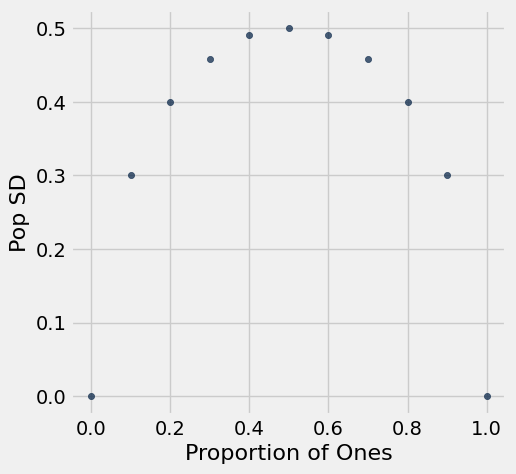

In [11]:
zero_one_pop.scatter('Proportion of Ones', 'Pop SD')

Example: a poll of 1,004 randomly sampled voters. Because the SD of a 0/1 population is at most 0.5, the total width of an approximate 95% confidence interval for the proportion of voters who favor a candidate is at most $4 \cdot \frac{0.5}{ \sqrt{1004}}$, no matter what that proportion is. Polls usually report the **margin of error $\epsilon$**, which is half the width of the interval: about 0.0316, or 3.16 percentage points.

In [12]:
4 * 0.5 / np.sqrt(1004)

0.063119440309780311

> **The worst case is 0.5** (half ones, half zeros). That means for any proportion, the 95% CI is *at most* $\pm2 \cdot \frac{0.5}{ \sqrt{n}}$ wide on each side, computable before you collect a single response!

### Try It 2: Design the poll 🗳️

1. You want a 95% confidence interval for a proportion with **total width at most 0.06** (±3 percentage points). What sample size guarantees it, even in the worst case? (*Total width* = $4 \cdot \frac{0.5}{ \sqrt{n}}$.)

In [13]:
# 1. smallest n with 4 * 0.5 / sqrt(n) <= 0.06


<details>
<summary>💡 Possible answers — click to peek</summary>
<br>

*Solve $\frac{2}{\sqrt{n}} \le 0.06 \rightarrow \sqrt{n} \ge 33.33 \rightarrow n \ge 1111.1 \rightarrow 1112$ people. (This is why real polls survey "about 1,100 adults"!)*

```python
# 1.
(2 / 0.06) ** 2          # 1111.1 → need n = 1112
4 * 0.5 / np.sqrt(1112)  # check: ≈ 0.0599 ✓
```

</details>

---
> **Today's takeaway:** CLT turns confidence intervals into arithmetic: $\text{mean} \pm 2 \cdot \frac{SD}{\sqrt{n}}$, and the 0.5 worst-case SD lets you budget a survey before it exists. You see this in Homework 8, sections 2 and 3!!!

## Appendix — Quick Reference

Full `datascience` docs: [data8.org/datascience](https://data8.org/datascience/)

### Sample size for a proportion
```python
# 95% CI total width <= w   =>   n >= (4 * 0.5 / w) ** 2
```